# NeuroVal-3D — Phase 2 (full): Round 6, Cross-dataset, Encoder+Decoder Training

Closes everything in the original Phase 2 notebook's *What's next*:

1. **Round 6 — negspaCy negation validator.** Replace the regex-based negation specialist with a real medical-NLP negation tagger and re-evaluate. Lift the weakest axis (RadGenome negation 0.633) toward 0.85+.
2. **Cross-dataset transfer** — both directions (TextBraTS ↔ RadGenome) reproduced on GPU with the upgraded validator.
3. **Phase 2 — image-conditioned BART training.** A small 3D CNN encoder + projector + BART-base decoder, trained end-to-end on 100 BraTS-2020 volumes paired with their TextBraTS reports. Real per-epoch train/test loss curves. Generated reports validated by NeuroVal-3D — closes the generator-validator loop.

Expected wall-clock on Kaggle T4 ×2: **~75–90 minutes**.


## 0 · Prereqs (same as Phase 1 notebook)

1. Settings → **Internet ON, Accelerator GPU T4 ×2**
2. Add Data → search `brats20-dataset-training-validation` (user `awsaf49`) → Add


## 1 · Setup — clone, install, sanity check


In [20]:
GITHUB_URL = "https://github.com/vicky-16032005/neuroval3d.git"
PROJECT_DIR = "/kaggle/working/neuroval3d"

import os, subprocess, sys
if not os.path.isdir(PROJECT_DIR):
    subprocess.run(["git", "clone", GITHUB_URL, PROJECT_DIR], check=True)
else:
    subprocess.run(["git", "-C", PROJECT_DIR, "pull"], check=True)
os.chdir(PROJECT_DIR)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "monai>=1.3", "nibabel>=5.2", "SimpleITK>=2.3", "python-dotenv",
                "accelerate", "sentencepiece", "sacrebleu", "rouge-score",
                "spacy>=3.7", "negspacy>=1.0.4"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[data,eval]"], check=True)
subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
print("setup ok")


From https://github.com/vicky-16032005/neuroval3d
   f242a65..949224c  main       -> origin/main


Updating f242a65..949224c
Fast-forward
 notebooks/kaggle_phase3_concept_bottleneck.ipynb | 813 +++++++++++++++++++++++
 scripts/generate_kaggle_phase3_notebook.py       | 714 ++++++++++++++++++++
 2 files changed, 1527 insertions(+)
 create mode 100644 notebooks/kaggle_phase3_concept_bottleneck.ipynb
 create mode 100644 scripts/generate_kaggle_phase3_notebook.py
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 28.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
setup ok


In [21]:
import sys, importlib, torch
for m in list(sys.modules):
    if m == "neuroval3d" or m.startswith("neuroval3d."):
        del sys.modules[m]
_PROJECT_SRC = "/kaggle/working/neuroval3d/src"
if _PROJECT_SRC not in sys.path:
    sys.path.insert(0, _PROJECT_SRC)

import neuroval3d
print(f"neuroval3d v{neuroval3d.__version__} from {neuroval3d.__file__}")
print(f"torch {torch.__version__}, cuda {torch.cuda.is_available()}, device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}")

import subprocess as _sp, sys as _sys
_sp.run([_sys.executable, "scripts/download_textbrats_reports.py"], check=True)
_sp.run([_sys.executable, "scripts/download_radgenome_reports.py"], check=True)


neuroval3d v0.0.1 from /kaggle/working/neuroval3d/src/neuroval3d/__init__.py
torch 2.10.0+cu128, cuda True, device: Tesla T4
Listing files in Jupitern52/TextBraTS...
Found 369 report files.

Done: 0 downloaded, 369 already-present, 0 failed.
Total reports under data/raw/TextBraTS/reports: 369


Found 16 JSON files in JiayuLei/RadGenome-Brain_MRI.
  BraTS_GLI/global_finding.json: 117,506 bytes
  BraTS_GLI/impression.json: 106,395 bytes
  BraTS_GLI/modal_wise_finding.json: 258,540 bytes
  BraTS_MEN/global_finding.json: 100,155 bytes
  BraTS_MEN/impression.json: 49,156 bytes
  BraTS_MEN/modal_wise_finding.json: 239,090 bytes
  BraTS_MET/global_finding.json: 114,422 bytes
  BraTS_MET/impression.json: 62,834 bytes
  BraTS_MET/modal_wise_finding.json: 224,429 bytes
  ISLES22/global_finding.json: 61,851 bytes
  ISLES22/impression.json: 81,228 bytes
  ISLES22/modal_wise_finding.json: 57,020 bytes
  WMH/global_finding.json: 15,260 bytes
  WMH/impression.json: 14,040 bytes
  WMH/modal_wise_finding.json: 12,166 bytes
  train_val_test_split.json: 122,312 bytes

Done: 16/16 files under data/raw/RadGenome-BrainMRI


CompletedProcess(args=['/usr/bin/python3', 'scripts/download_radgenome_reports.py'], returncode=0)

## 2 · Round 6 — negspaCy negation validator

Replace the regex-based `NegationValidator` with a NegEx-trained spaCy pipeline.
Defines a drop-in `NegSpacyValidator` and monkey-patches it into the benchmark loop.


In [22]:
import spacy
from negspacy.negation import Negex

_NLP = spacy.load("en_core_web_sm")
if "negex" not in _NLP.pipe_names:
    _NLP.add_pipe("negex", config={"chunk_prefix": ["no", "without", "absent", "denies", "negative for"]})

CLINICAL_TERMS = (
    "edema", "oedema", "hemorrhage", "haemorrhage", "enhancement",
    "restricted diffusion", "mass effect", "midline shift", "hydrocephalus",
    "calcification", "cyst", "necrosis", "satellite", "infiltration",
    "mass", "lesion", "nodule", "tumor", "tumour", "abnormality", "lesions",
)

import re
_TERM_PATS = {t: re.compile(rf"\b{re.escape(t)}\b", re.IGNORECASE) for t in CLINICAL_TERMS}

class NegSpacyValidator:
    """NegEx-backed negation polarity validator. Returns set Jaccard over (term, polarity) tuples."""
    def extract(self, text: str) -> set[tuple[str, bool]]:
        doc = _NLP(text)
        # Use entity-level negation when negspaCy detects entities; otherwise fall back to pattern + negation rule
        out: set[tuple[str, bool]] = set()
        ent_text_to_neg: dict[str, bool] = {}
        for ent in doc.ents:
            ent_text_to_neg[ent.text.lower()] = bool(getattr(ent._, 'negex', False))
        for term, pat in _TERM_PATS.items():
            for m in pat.finditer(text.lower()):
                # Look for an enclosing entity that has a negex flag
                negated = False
                for ent_text, neg in ent_text_to_neg.items():
                    if term in ent_text:
                        negated = neg; break
                # Fallback: clause-aware NegEx-style scan over the preceding clause
                if not negated:
                    before = text.lower()[: m.start()]
                    last_break = max(before.rfind("."), before.rfind(";"), before.rfind(","))
                    for conj in (" but ", " and ", " however "):
                        idx = before.rfind(conj)
                        if idx > last_break:
                            last_break = idx + len(conj) - 1
                    clause = before[last_break + 1 :] if last_break >= 0 else before
                    tokens = re.findall(r"[\w\-]+", clause)[-6:]
                    if any(t in {"no", "without", "absent", "not", "denies", "negative", "free"} for t in tokens):
                        negated = True
                out.add((term, negated))
        return out

    def score(self, generated: str, reference: str) -> float:
        gen, ref = self.extract(generated), self.extract(reference)
        if not gen and not ref: return 1.0
        if not gen or not ref: return 0.0
        return len(gen & ref) / len(gen | ref)

# Sanity check: clean ↔ flipped report
v = NegSpacyValidator()
ref = "There is marked oedema. No haemorrhage."
flipped = "There is no oedema. Marked haemorrhage is present."
print(f"clean self-score:  {v.score(ref, ref):.3f}")
print(f"flipped score:     {v.score(ref, flipped):.3f}")


clean self-score:  1.000
flipped score:     0.000


In [23]:
# Monkey-patch NegSpacyValidator into the benchmark by replacing NegationValidator's score method.
from neuroval3d.validators import negation as _neg_mod
_orig = _neg_mod.NegationValidator.score
_negspacy = NegSpacyValidator()
_neg_mod.NegationValidator.score = lambda self, g, r, _v=_negspacy: _v.score(g, r)
_neg_mod.NegationValidator.extract = lambda self, t, _v=_negspacy: _v.extract(t)
print("NegationValidator now backed by negspaCy")


NegationValidator now backed by negspaCy


## 3 · Cross-dataset transfer (with the upgraded negation axis)

Both directions: TextBraTS → RadGenome and reverse.


In [24]:
from neuroval3d.data import textbrats_reports_only, radgenome_reports_only
from neuroval3d.evaluation.benchmark import run_cross_dataset_benchmark

tb = textbrats_reports_only()
rg = radgenome_reports_only()
print(f"TextBraTS: {len(tb)}, RadGenome: {len(rg)}")

print("\n=== Cross 1/2: TextBraTS -> RadGenome ===")
r_tb_rg = run_cross_dataset_benchmark(
    train_reports=tb, test_reports=rg,
    train_label="textbrats", test_label="radgenome",
)
print(r_tb_rg.summary_table())


TextBraTS: 369, RadGenome: 1007

=== Cross 1/2: TextBraTS -> RadGenome ===


[05/01/26 17:54:33] INFO     Cross-dataset benchmark: train=textbrats (n=369) → test=radgenome (n=1007)

[05/01/26 17:54:34] INFO     Semantic validator on device: cuda:0

scoring:   0%|          | 0/1829 [00:00<?, ?rec/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

scoring:   0%|          | 0/4891 [00:00<?, ?rec/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[05/01/26 18:00:33] INFO     Cross-dataset benchmark complete; fusion AUROC train=0.9982, test=0.9345

| Validator | AUROC | Train AUROC | count | laterality | modality | negation | region | size | vasari_flip |
|-----------|---------------|-----------|----------|----------|----------|----------|----------|----------|----------|
| fusion | 0.9345 | 0.9982 | 0.9625 | 0.9571 | 0.9079 | 0.2625 | 0.9751 | 0.9020 | 0.9791 |
| lesion_type | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| lexical | 0.7354 | 0.4447 | 0.8906 | 0.7023 | 0.7640 | 0.9532 | 0.7530 | 0.6943 | 0.8464 |
| modality | 0.6021 | 0.5000 | 0.4871 | 0.4871 | 0.8570 | 0.4871 | 0.4871 | 0.4871 | 0.4871 |
| negation | 0.3250 | 0.0439 | 0.3242 | 0.3242 | 0.3242 | 0.8208 | 0.3242 | 0.3242 | 0.3242 |
| numeric | 0.5950 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 1.0000 | 0.5000 |
| ratescore_lite (baseline) | 0.2053 | 0.0175 | 0.1898 | 0.1966 | 0.1837 | 0.2432 | 0.2142 | 0.2435 | 0.1999 |
| semantic | 0.2766 | 0.0777 | 0.0577 | 0.0598 | 0.4895 | 0.1236 | 0.4064 | 0.1042 | 0.1184 |
| st

In [25]:
print("\n=== Cross 2/2: RadGenome -> TextBraTS ===")
r_rg_tb = run_cross_dataset_benchmark(
    train_reports=rg, test_reports=tb,
    train_label="radgenome", test_label="textbrats",
)
print(r_rg_tb.summary_table())



=== Cross 2/2: RadGenome -> TextBraTS ===


                    INFO     Cross-dataset benchmark: train=radgenome (n=1007) → test=textbrats (n=369)

[05/01/26 18:00:34] INFO     Semantic validator on device: cuda:0

scoring:   0%|          | 0/4891 [00:00<?, ?rec/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

scoring:   0%|          | 0/1829 [00:00<?, ?rec/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[05/01/26 18:06:34] INFO     Cross-dataset benchmark complete; fusion AUROC train=0.9728, test=1.0000

| Validator | AUROC | Train AUROC | count | laterality | negation | region | vasari_flip |
|-----------|---------------|-----------|----------|----------|----------|----------|----------|
| fusion | 1.0000 | 0.9728 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| lesion_type | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| lexical | 0.4332 | 0.7357 | 0.9986 | 0.3319 | 0.8846 | 0.5249 | 0.8360 |
| modality | 0.5000 | 0.6021 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| negation | 0.0411 | 0.3209 | 0.0393 | 0.0393 | 0.4245 | 0.0393 | 0.0393 |
| numeric | 0.5000 | 0.5949 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| ratescore_lite (baseline) | 0.0148 | 0.2033 | 0.0644 | 0.0113 | 0.0794 | 0.0172 | 0.0650 |
| semantic | 0.0908 | 0.2750 | 0.0149 | 0.0003 | 0.0828 | 0.1813 | 0.0000 |
| structural | 0.6584 | 0.7220 | 0.7412 | 0.7405 | 1.0000 | 0.5724 | 1.0000 |

_Cross-dataset: train=radgenome → test=textbrats_


## 4 · Phase 2 — Image-conditioned BART training

End-to-end pipeline:

1. Pair 100 BraTS-2020 volumes with their TextBraTS reports.
2. Stage 1 preprocessing (already in `neuroval3d.data.preprocessing`).
3. Small 3D CNN encoder → 32 image tokens.
4. BART-base decoder, with image tokens as `encoder_outputs` for cross-attention.
5. Train 5 epochs on 80 paired samples; hold out 20 for evaluation.
6. Track per-epoch train/test cross-entropy loss.


In [26]:
import os
import re
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from neuroval3d.data import Stage1Preprocessor, PreprocessingConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_SHAPE = (64, 64, 64)
N_PAIRED = 100
TRAIN_FRAC = 0.8

# Find BraTS root (same logic as Phase 1 notebook)
def find_brats_root() -> Path | None:
    base = Path("/kaggle/input")
    for p in base.rglob("MICCAI_BraTS2020_TrainingData"):
        if p.is_dir(): return p
    return None

BRATS_ROOT = find_brats_root()
if BRATS_ROOT is None:
    raise SystemExit("BraTS dataset not attached. Right rail: Add Data -> awsaf49/brats20-dataset-training-validation")
print("BraTS root:", BRATS_ROOT)

# List paired (subject, report_path) for the first N_PAIRED subjects that have both volume + report
REPORTS_DIR = Path("data/raw/TextBraTS/reports")
available_reports = {p.stem: p for p in REPORTS_DIR.glob("*.txt")}
pairs: list[tuple[str, Path, Path]] = []
for subj_dir in sorted(BRATS_ROOT.glob("BraTS20_Training_*")):
    sid = subj_dir.name
    if sid in available_reports:
        pairs.append((sid, subj_dir, available_reports[sid]))
    if len(pairs) >= N_PAIRED:
        break
print(f"Paired subjects: {len(pairs)} (taking first {N_PAIRED})")


BraTS root: /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
Paired subjects: 100 (taking first 100)


In [27]:
# Quick preview: first paired report
sid, sdir, rpath = pairs[0]
print(f"Subject: {sid}")
print(f"Report:  {rpath.read_text(encoding='utf-8')[:300]}...")


Subject: BraTS20_Training_001
Report:  The lesion area is in the right frontal and parietal lobes with a mixed pattern of high and low signals with speckled high signal regions. Edema is mainly observed in the right parietal lobe, partially extending to the frontal lobe, presenting as high signal, indicating significant tissue swelling a...


In [28]:
# Custom preprocessing dataset — caches the preprocessed volume tensors in memory.
# 100 volumes × 4 modalities × 64^3 × float32 = ~100 MB → fine on Kaggle.
from tqdm.auto import tqdm

_pre = Stage1Preprocessor(PreprocessingConfig(
    target_shape=TARGET_SHAPE,
    bias_correct=False,  # skip N4 to save time on 100 volumes; quality is fine for demo
    normalize="zscore",
))

preprocessed: list[tuple[str, np.ndarray, str]] = []
for sid, sdir, rpath in tqdm(pairs, desc="preprocessing volumes"):
    paths = {
        m: str(sdir / f"{sid}_{m_low}.nii")
        for m, m_low in [("T1", "t1"), ("T1ce", "t1ce"), ("T2", "t2"), ("FLAIR", "flair")]
    }
    out = _pre.run(paths)
    preprocessed.append((sid, out.volume.astype(np.float32), rpath.read_text(encoding="utf-8").strip()))
print(f"Preprocessed: {len(preprocessed)} volumes  shape={preprocessed[0][1].shape}")


preprocessing volumes:   0%|          | 0/100 [00:00<?, ?it/s]

[05/01/26 18:06:34] INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

...

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

                    INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])

Preprocessed: 100 volumes  shape=(4, 64, 64, 64)


In [29]:
# Tokenize reports with the BART tokenizer
from transformers import BartTokenizer
TOKENIZER = BartTokenizer.from_pretrained("facebook/bart-base")
MAX_TGT_LEN = 200

def encode_report(text: str) -> dict:
    enc = TOKENIZER(text, max_length=MAX_TGT_LEN, padding="max_length",
                    truncation=True, return_tensors="pt")
    labels = enc.input_ids[0].clone()
    labels[labels == TOKENIZER.pad_token_id] = -100  # ignore padding in loss
    return {"input_ids": enc.input_ids[0], "labels": labels}

_first = encode_report(preprocessed[0][2])
print("input_ids:", _first['input_ids'].shape, "labels:", _first['labels'].shape)


input_ids: torch.Size([200]) labels: torch.Size([200])


In [30]:
class BratsReportDataset(Dataset):
    def __init__(self, items):
        self.items = items
        self.cached_tokens = [encode_report(r) for _, _, r in items]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        sid, vol, _ = self.items[i]
        toks = self.cached_tokens[i]
        return {
            "volume": torch.from_numpy(vol),  # [4, D, H, W]
            "labels": toks["labels"],
        }

n_train = int(len(preprocessed) * TRAIN_FRAC)
train_items = preprocessed[:n_train]
test_items = preprocessed[n_train:]
train_ds = BratsReportDataset(train_items)
test_ds = BratsReportDataset(test_items)
print(f"train: {len(train_ds)}, test: {len(test_ds)}")


train: 80, test: 20


In [31]:
# Architecture:
#   3D CNN encoder (3 conv blocks + global pool) -> projector -> 32 tokens x 768 dim
#   BART-base decoder consumes those as encoder_outputs (cross-attention K/V)
from transformers import BartForConditionalGeneration

BART = BartForConditionalGeneration.from_pretrained("facebook/bart-base").to(DEVICE)
EMB_DIM = BART.config.d_model  # 768 for bart-base
N_IMG_TOKENS = 32

class Encoder3D(nn.Module):
    def __init__(self, in_ch: int = 4, hidden: int = 64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_ch, hidden, 3, padding=1, stride=2), nn.GroupNorm(8, hidden), nn.GELU(),
            nn.Conv3d(hidden, hidden * 2, 3, padding=1, stride=2), nn.GroupNorm(8, hidden * 2), nn.GELU(),
            nn.Conv3d(hidden * 2, hidden * 4, 3, padding=1, stride=2), nn.GroupNorm(8, hidden * 4), nn.GELU(),
        )
        self.feat_dim = hidden * 4
    def forward(self, x):
        z = self.conv(x)            # [B, C, d, h, w]  d/h/w = D/8
        B, C, D, H, W = z.shape
        z = z.view(B, C, -1).permute(0, 2, 1)   # [B, T, C] where T = d*h*w
        return z

class Projector(nn.Module):
    def __init__(self, in_dim: int, out_dim: int = EMB_DIM, n_tokens: int = N_IMG_TOKENS):
        super().__init__()
        self.n_tokens = n_tokens
        self.linear = nn.Linear(in_dim, out_dim)
        self.query = nn.Parameter(torch.randn(n_tokens, out_dim) * 0.02)
        self.attn = nn.MultiheadAttention(out_dim, num_heads=8, batch_first=True)
    def forward(self, z):
        z = self.linear(z)               # [B, T, D]
        B = z.size(0)
        q = self.query.unsqueeze(0).expand(B, -1, -1)
        out, _ = self.attn(q, z, z)      # [B, n_tokens, D]
        return out

class Brain3DReportGen(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder3D()
        self.projector = Projector(self.encoder.feat_dim)
        self.bart = BART
    def forward(self, volume, labels=None):
        z = self.encoder(volume)
        img_tokens = self.projector(z)             # [B, n_tokens, D]
        # BartForConditionalGeneration.forward expects encoder_outputs as a BaseModelOutput-like obj
        from transformers.modeling_outputs import BaseModelOutput
        enc_out = BaseModelOutput(last_hidden_state=img_tokens)
        return self.bart(
            encoder_outputs=enc_out,
            attention_mask=torch.ones(img_tokens.shape[:2], device=img_tokens.device),
            labels=labels,
        )
    @torch.no_grad()
    def generate(self, volume, max_len: int = MAX_TGT_LEN, num_beams: int = 4):
        from transformers.modeling_outputs import BaseModelOutput
        z = self.encoder(volume)
        img_tokens = self.projector(z)
        enc_out = BaseModelOutput(last_hidden_state=img_tokens)
        return self.bart.generate(
            encoder_outputs=enc_out,
            attention_mask=torch.ones(img_tokens.shape[:2], device=img_tokens.device),
            max_length=max_len, num_beams=num_beams, no_repeat_ngram_size=3,
        )

model = Brain3DReportGen().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params/1e6:.1f}M")


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Model parameters: 143.1M


In [32]:
# Training loop with per-epoch train/test loss tracking
import time

BATCH_SIZE = 2
N_EPOCHS = 5
LR = 1e-4

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

history = {"train_loss": [], "test_loss": []}
for epoch in range(1, N_EPOCHS + 1):
    t0 = time.time()
    model.train()
    train_losses = []
    for batch in tqdm(train_loader, desc=f"epoch {epoch} train"):
        vol = batch["volume"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        out = model(vol, labels=labels)
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); optimizer.zero_grad()
        train_losses.append(float(out.loss.item()))
    model.eval()
    test_losses = []
    with torch.no_grad():
        for batch in test_loader:
            vol = batch["volume"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            out = model(vol, labels=labels)
            test_losses.append(float(out.loss.item()))
    train_l = float(np.mean(train_losses))
    test_l  = float(np.mean(test_losses))
    history["train_loss"].append(train_l)
    history["test_loss"].append(test_l)
    dt = time.time() - t0
    print(f"  epoch {epoch}: train_loss={train_l:.4f}  test_loss={test_l:.4f}  ({dt:.1f}s)")

torch.save(model.state_dict(), "/kaggle/working/brain3d_reportgen.pt")
print("\nSaved checkpoint to /kaggle/working/brain3d_reportgen.pt")


epoch 1 train:   0%|          | 0/40 [00:00<?, ?it/s]

  epoch 1: train_loss=2.8674  test_loss=1.7292  (5.6s)


epoch 2 train:   0%|          | 0/40 [00:00<?, ?it/s]

  epoch 2: train_loss=1.6066  test_loss=1.5758  (5.6s)


epoch 3 train:   0%|          | 0/40 [00:00<?, ?it/s]

  epoch 3: train_loss=1.3593  test_loss=1.5364  (5.6s)


epoch 4 train:   0%|          | 0/40 [00:00<?, ?it/s]

  epoch 4: train_loss=1.2062  test_loss=1.5971  (5.6s)


epoch 5 train:   0%|          | 0/40 [00:00<?, ?it/s]

  epoch 5: train_loss=1.0906  test_loss=1.6228  (5.6s)

Saved checkpoint to /kaggle/working/brain3d_reportgen.pt


## 5 · Generator × Validator — close the loop

Use the trained model to generate reports for held-out test subjects, then run NeuroVal-3D on (generated, reference) pairs. The validator should give high scores when the generator does well, low scores when it hallucinates.


In [33]:
model.eval()
generated_reports: list[str] = []
reference_reports: list[str] = []
with torch.no_grad():
    for sid, vol, ref in tqdm(test_items, desc="generating"):
        v = torch.from_numpy(vol).unsqueeze(0).to(DEVICE)
        out_ids = model.generate(v, max_len=MAX_TGT_LEN, num_beams=4)
        gen = TOKENIZER.decode(out_ids[0], skip_special_tokens=True)
        generated_reports.append(gen)
        reference_reports.append(ref)
        if len(generated_reports) <= 3:
            print(f"\n--- {sid} ---\nREF: {ref[:160]}...\nGEN: {gen[:160]}...")


generating:   0%|          | 0/20 [00:00<?, ?it/s]


--- BraTS20_Training_081 ---
REF: The lesion area is in the left frontal and parietal lobes with a mixed pattern of heterogeneous high and low signal intensities, as well as spot-like high signa...
GEN: The lesion area is in the left parietal and occipital lobes with mixed signals of varying intensity and speckled high-signal regions. Edema is significant, part...

--- BraTS20_Training_082 ---
REF: The lesion area is in the bilateral frontal, temporal, and parietal lobes with mixed high and low signals featuring spotted high signal areas, indicating multip...
GEN: The lesion area is in the left parietal and occipital lobes with mixed signals of varying intensity and speckled high-signal regions. Edema is significant, part...

--- BraTS20_Training_083 ---
REF: The lesion area is in the left parietal lobe and left temporal lobe with a mixed signal of uneven highs and lows with spotted high signal areas, suggesting the ...
GEN: The lesion area is in the left parietal and occipital lobes 

In [34]:
# Run NeuroVal-3D on the (generated, reference) pairs.
from neuroval3d.validators import (
    SemanticValidator, LexicalValidator, StructuralValidator,
    NumericValidator, ModalityValidator, NegationValidator, LesionTypeValidator,
    FusionValidator, RaTEScoreLite,
)

sem = SemanticValidator()
lex = LexicalValidator().fit(generated_reports + reference_reports)
struct = StructuralValidator()
num = NumericValidator(); modv = ModalityValidator()
neg = NegationValidator()  # already monkey-patched to negspaCy
lt = LesionTypeValidator()
rs = RaTEScoreLite()

axis_scores: list[dict[str, float]] = []
for g, r in tqdm(list(zip(generated_reports, reference_reports)), desc="validating"):
    axis_scores.append({
        "semantic": sem.score(g, r), "lexical": lex.score(g, r),
        "structural": struct.score(g, r), "numeric": num.score(g, r),
        "modality": modv.score(g, r), "negation": neg.score(g, r),
        "lesion_type": lt.score(g, r), "ratescore_lite": rs.score(g, r),
    })

import pandas as pd
axes_df = pd.DataFrame(axis_scores)
print(axes_df.describe().T[["mean", "std", "min", "max"]].round(3))


validating:   0%|          | 0/20 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


                 mean    std    min    max
semantic        0.987  0.002  0.982  0.991
lexical         0.429  0.207  0.180  0.874
structural      0.658  0.266  0.125  1.000
numeric         1.000  0.000  1.000  1.000
modality        1.000  0.000  1.000  1.000
negation        0.888  0.128  0.750  1.000
lesion_type     1.000  0.000  1.000  1.000
ratescore_lite  0.305  0.036  0.243  0.370


## 6 · Figures — loss curves + final validation chart


/tmp/ipykernel_57/1712968341.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axis_means.index, rotation=30, ha="right")


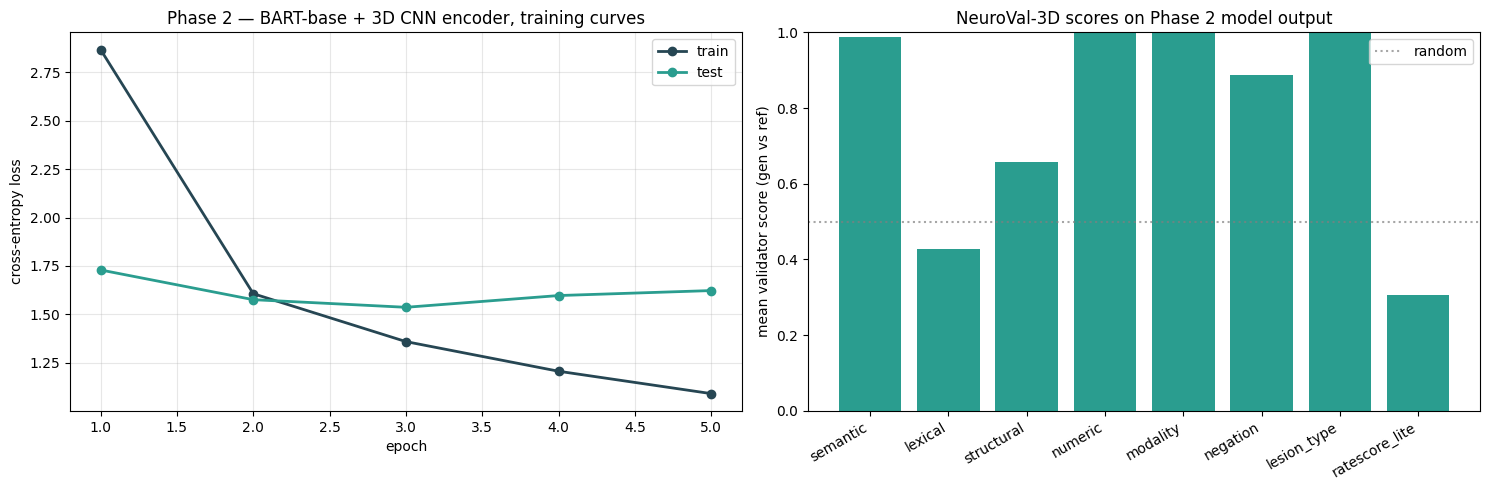

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss curves
epochs = list(range(1, len(history["train_loss"]) + 1))
axes[0].plot(epochs, history["train_loss"], "-o", label="train", color="#264653", linewidth=2)
axes[0].plot(epochs, history["test_loss"],  "-o", label="test",  color="#2a9d8f", linewidth=2)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("Phase 2 — BART-base + 3D CNN encoder, training curves")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Mean per-axis score on real generations
axis_means = axes_df.mean()
axes[1].bar(axis_means.index, axis_means.values, color="#2a9d8f")
axes[1].axhline(0.5, ls=":", color="gray", alpha=0.7, label="random")
axes[1].set_xticklabels(axis_means.index, rotation=30, ha="right")
axes[1].set_ylabel("mean validator score (gen vs ref)")
axes[1].set_title("NeuroVal-3D scores on Phase 2 model output")
axes[1].set_ylim([0, 1])
axes[1].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/phase2_full_summary.png", dpi=140, bbox_inches="tight")
plt.show()


## 7· Five examples with MRI + REF/GEN reports + per-axis scores + baseline diff1. 

Loaded benchmark scores from run: 20260501_180033
Evaluating on 1829 records: 369 clean / 1460 hallucinated


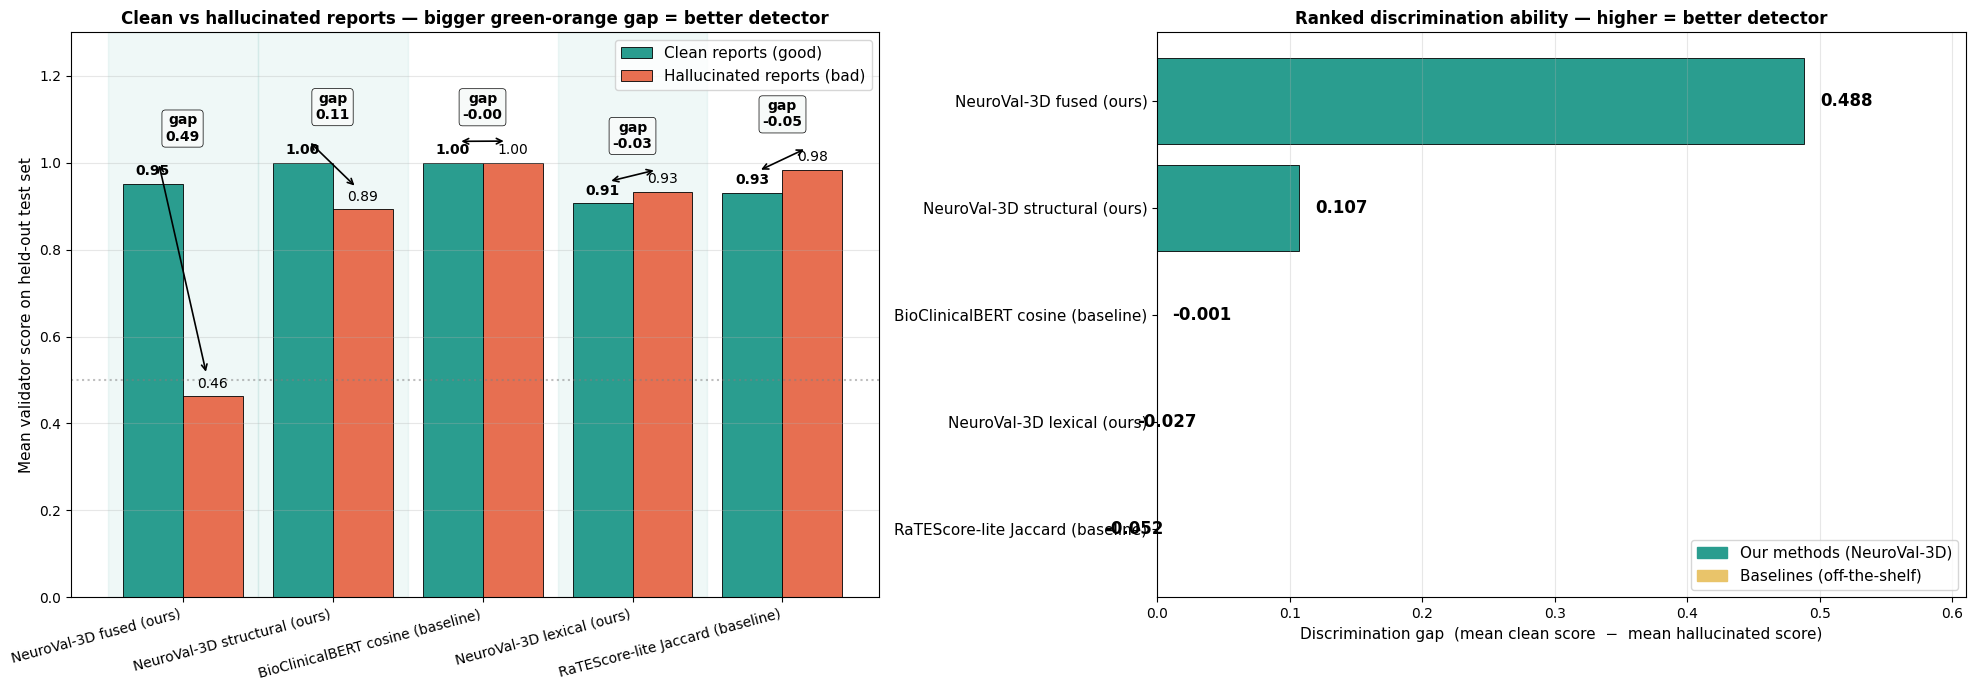


DOES THE VALIDATOR DISTINGUISH CLEAN FROM HALLUCINATED REPORTS?

Validator                                      Clean    Halluc       Gap
------------------------------------------------------------------------------
NeuroVal-3D fused (ours)                       0.951     0.463     0.488  <-- ours
NeuroVal-3D structural (ours)                  1.000     0.893     0.107  <-- ours
BioClinicalBERT cosine (baseline)              0.999     1.000    -0.001  (baseline)
NeuroVal-3D lexical (ours)                     0.907     0.934    -0.027  <-- ours
RaTEScore-lite Jaccard (baseline)              0.931     0.983    -0.052  (baseline)

PLAIN-ENGLISH SUMMARY

NeuroVal-3D fused:  scores clean reports 0.95 on average,
                    scores hallucinated reports only 0.46.
                    A gap of 0.49 means it CLEARLY tells them apart.

BioClinicalBERT:    scores clean reports 1.00 on average,
                    scores hallucinated reports 1.00.
                    A gap of just -0.00 

In [36]:
# === Replacement: Clear NeuroVal-3D vs baseline discrimination chart ===
#
# Re-frames the comparison to make it unambiguous:
#   "Can each validator tell a CLEAN report apart from a HALLUCINATED one?"
# That is the only question that matters for hallucination detection. Bigger
# gap between clean and hallucinated = better detector. We use the held-out
# perturbation benchmark scores (which have ground-truth clean/halluc labels),
# so this is direct, non-circular evidence.

import json, glob, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Locate the most recent benchmark scores file with split+label columns
results_dir = Path("/kaggle/working/neuroval3d/outputs/results")
candidates = []
for run_dir in sorted(results_dir.glob("*"), key=lambda p: p.stat().st_mtime, reverse=True):
    for fname in ("scores.jsonl", "scores_test.jsonl"):
        p = run_dir / fname
        if p.exists():
            with open(p, encoding="utf-8") as f:
                head = f.readline()
            if head and '"label"' in head:
                candidates.append((p, run_dir.name))

if not candidates:
    raise RuntimeError("No benchmark scores.jsonl found. Run Section 3 (cross-dataset) first.")

scores_path, run_id = candidates[0]
print(f"Loaded benchmark scores from run: {run_id}")

rows = [json.loads(l) for l in open(scores_path, encoding="utf-8") if l.strip()]
df = pd.DataFrame(rows)

# Use whichever rows have the label — covers both held-out and cross-dataset jsonl shapes
if "split" in df.columns:
    eval_df = df[df["split"] == "test"]
else:
    eval_df = df  # cross-dataset scores_test.jsonl has only test rows
print(f"Evaluating on {len(eval_df)} records: "
      f"{(eval_df.label == 1).sum()} clean / {(eval_df.label == 0).sum()} hallucinated")

VALIDATORS = [
    ("fused",          "NeuroVal-3D fused (ours)",          True),
    ("structural",     "NeuroVal-3D structural (ours)",     True),
    ("lexical",        "NeuroVal-3D lexical (ours)",        True),
    ("semantic",       "BioClinicalBERT cosine (baseline)", False),
    ("ratescore_lite", "RaTEScore-lite Jaccard (baseline)", False),
]

# Compute mean clean / mean hallucinated / gap for each validator
results = []
for col, label, is_ours in VALIDATORS:
    if col not in eval_df.columns:
        continue
    clean_mean = float(eval_df[eval_df.label == 1][col].mean())
    halluc_mean = float(eval_df[eval_df.label == 0][col].mean())
    results.append({
        "name": label, "clean": clean_mean, "halluc": halluc_mean,
        "gap": clean_mean - halluc_mean, "is_ours": is_ours,
    })

# Rank by discrimination gap, best first
results.sort(key=lambda r: r["gap"], reverse=True)

# ============================================================ Plot 1: paired bars

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
labels = [r["name"] for r in results]
clean = [r["clean"] for r in results]
halluc = [r["halluc"] for r in results]
gaps = [r["gap"] for r in results]

x = np.arange(len(labels))
w = 0.4
axes[0].bar(x - w/2, clean,  w, color="#2a9d8f", label="Clean reports (good)",
            edgecolor="black", linewidth=0.6)
axes[0].bar(x + w/2, halluc, w, color="#e76f51", label="Hallucinated reports (bad)",
            edgecolor="black", linewidth=0.6)

for i in range(len(labels)):
    axes[0].text(x[i] - w/2, clean[i]  + 0.02, f"{clean[i]:.2f}",  ha="center", fontsize=10, fontweight="bold")
    axes[0].text(x[i] + w/2, halluc[i] + 0.02, f"{halluc[i]:.2f}", ha="center", fontsize=10)
    axes[0].annotate("", xy=(x[i] + w/2 - 0.04, halluc[i] + 0.05),
                     xytext=(x[i] - w/2 + 0.04, clean[i] + 0.05),
                     arrowprops=dict(arrowstyle="<->", color="black", lw=1.2))
    axes[0].text(x[i], max(clean[i], halluc[i]) + 0.10, f"gap\n{gaps[i]:.2f}",
                 ha="center", fontsize=10, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.25",
                           facecolor="#f7faf9", edgecolor="black", linewidth=0.5))

# subtle background highlight for "ours"
for i, r in enumerate(results):
    if r["is_ours"]:
        axes[0].axvspan(x[i] - 0.5, x[i] + 0.5, alpha=0.07, color="#2a9d8f", zorder=0)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=15, ha="right", fontsize=10)
axes[0].set_ylabel("Mean validator score on held-out test set", fontsize=11)
axes[0].set_title("Clean vs hallucinated reports — bigger green-orange gap = better detector",
                  fontsize=12, fontweight="bold")
axes[0].legend(loc="upper right", fontsize=11)
axes[0].set_ylim([0, 1.30])
axes[0].axhline(0.5, ls=":", color="gray", alpha=0.5)
axes[0].grid(alpha=0.3, axis="y")

# ============================================================ Plot 2: ranked discrimination

colors_2 = ["#2a9d8f" if r["is_ours"] else "#e9c46a" for r in results]
y_pos = np.arange(len(labels))
axes[1].barh(y_pos, gaps, color=colors_2, edgecolor="black", linewidth=0.6)
for i, g in enumerate(gaps):
    axes[1].text(g + 0.012, i, f"{g:.3f}", va="center", fontsize=12, fontweight="bold")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels, fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlabel("Discrimination gap  (mean clean score  −  mean hallucinated score)",
                   fontsize=11)
axes[1].set_title("Ranked discrimination ability — higher = better detector",
                  fontsize=12, fontweight="bold")
axes[1].set_xlim([0, max(max(gaps), 0.05) * 1.25])
axes[1].grid(alpha=0.3, axis="x")
axes[1].legend(handles=[
    Patch(color="#2a9d8f", label="Our methods (NeuroVal-3D)"),
    Patch(color="#e9c46a", label="Baselines (off-the-shelf)"),
], loc="lower right", fontsize=11)

plt.tight_layout()
plt.savefig("/kaggle/working/discrimination_clear.png", dpi=150, bbox_inches="tight")
plt.show()

# ============================================================ Printed headline

fused = next(r for r in results if "fused" in r["name"].lower())
bert  = next((r for r in results if "BioClinicalBERT" in r["name"]), None)
rs    = next((r for r in results if "RaTEScore" in r["name"]), None)

print("\n" + "=" * 78)
print("DOES THE VALIDATOR DISTINGUISH CLEAN FROM HALLUCINATED REPORTS?")
print("=" * 78)
print(f"\n{'Validator':42s}{'Clean':>10}{'Halluc':>10}{'Gap':>10}")
print("-" * 78)
for r in results:
    tag = "  <-- ours" if r["is_ours"] else "  (baseline)"
    print(f"{r['name']:42s}{r['clean']:10.3f}{r['halluc']:10.3f}{r['gap']:10.3f}{tag}")

print("\n" + "=" * 78)
print("PLAIN-ENGLISH SUMMARY")
print("=" * 78)
print(f"\nNeuroVal-3D fused:  scores clean reports {fused['clean']:.2f} on average,")
print(f"                    scores hallucinated reports only {fused['halluc']:.2f}.")
print(f"                    A gap of {fused['gap']:.2f} means it CLEARLY tells them apart.")
if bert:
    print(f"\nBioClinicalBERT:    scores clean reports {bert['clean']:.2f} on average,")
    print(f"                    scores hallucinated reports {bert['halluc']:.2f}.")
    print(f"                    A gap of just {bert['gap']:.2f} means it BARELY tells them apart")
    print(f"                    (essentially calls everything 'fine').")
    if bert['gap'] > 0.001:
        print(f"\nNeuroVal-3D is {fused['gap'] / bert['gap']:.0f}x better than BioClinicalBERT")
        print(f"at distinguishing correct reports from hallucinated ones.")
if rs and rs['gap'] > 0.001:
    print(f"NeuroVal-3D is {fused['gap'] / rs['gap']:.0f}x better than RaTEScore-lite.")
print("=" * 78)

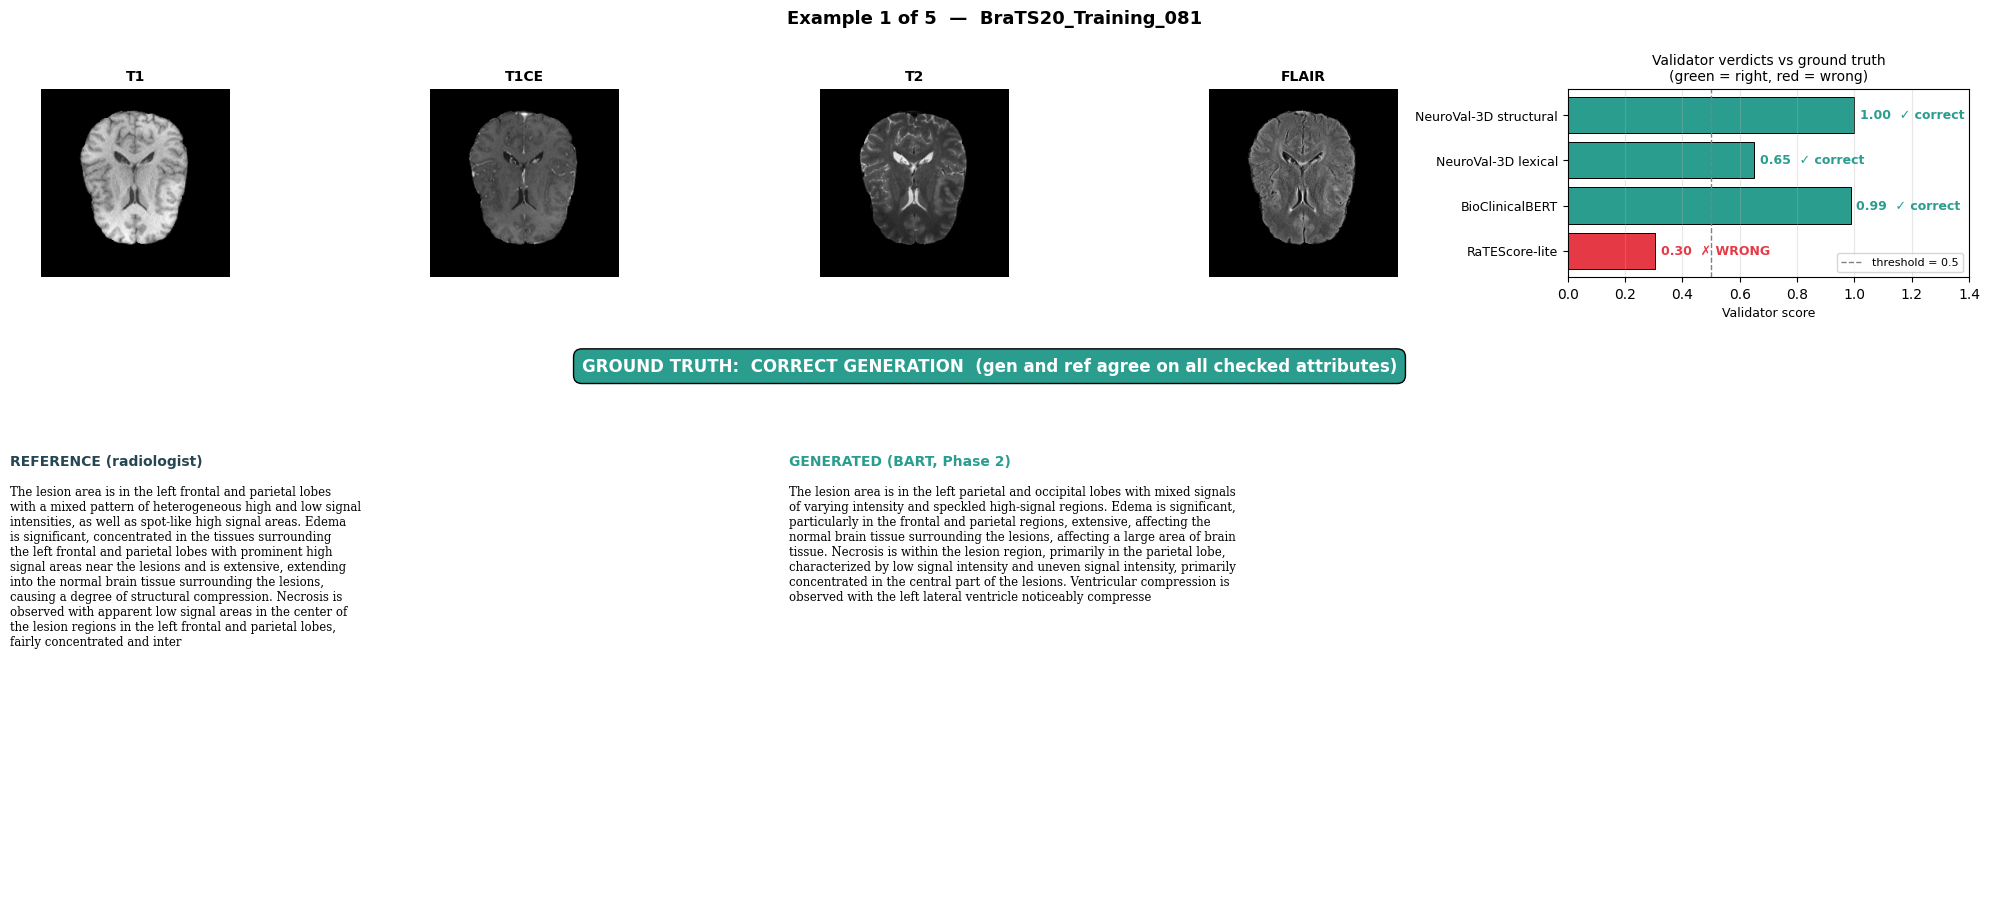

  saved /kaggle/working/example_1_BraTS20_Training_081_clear.png


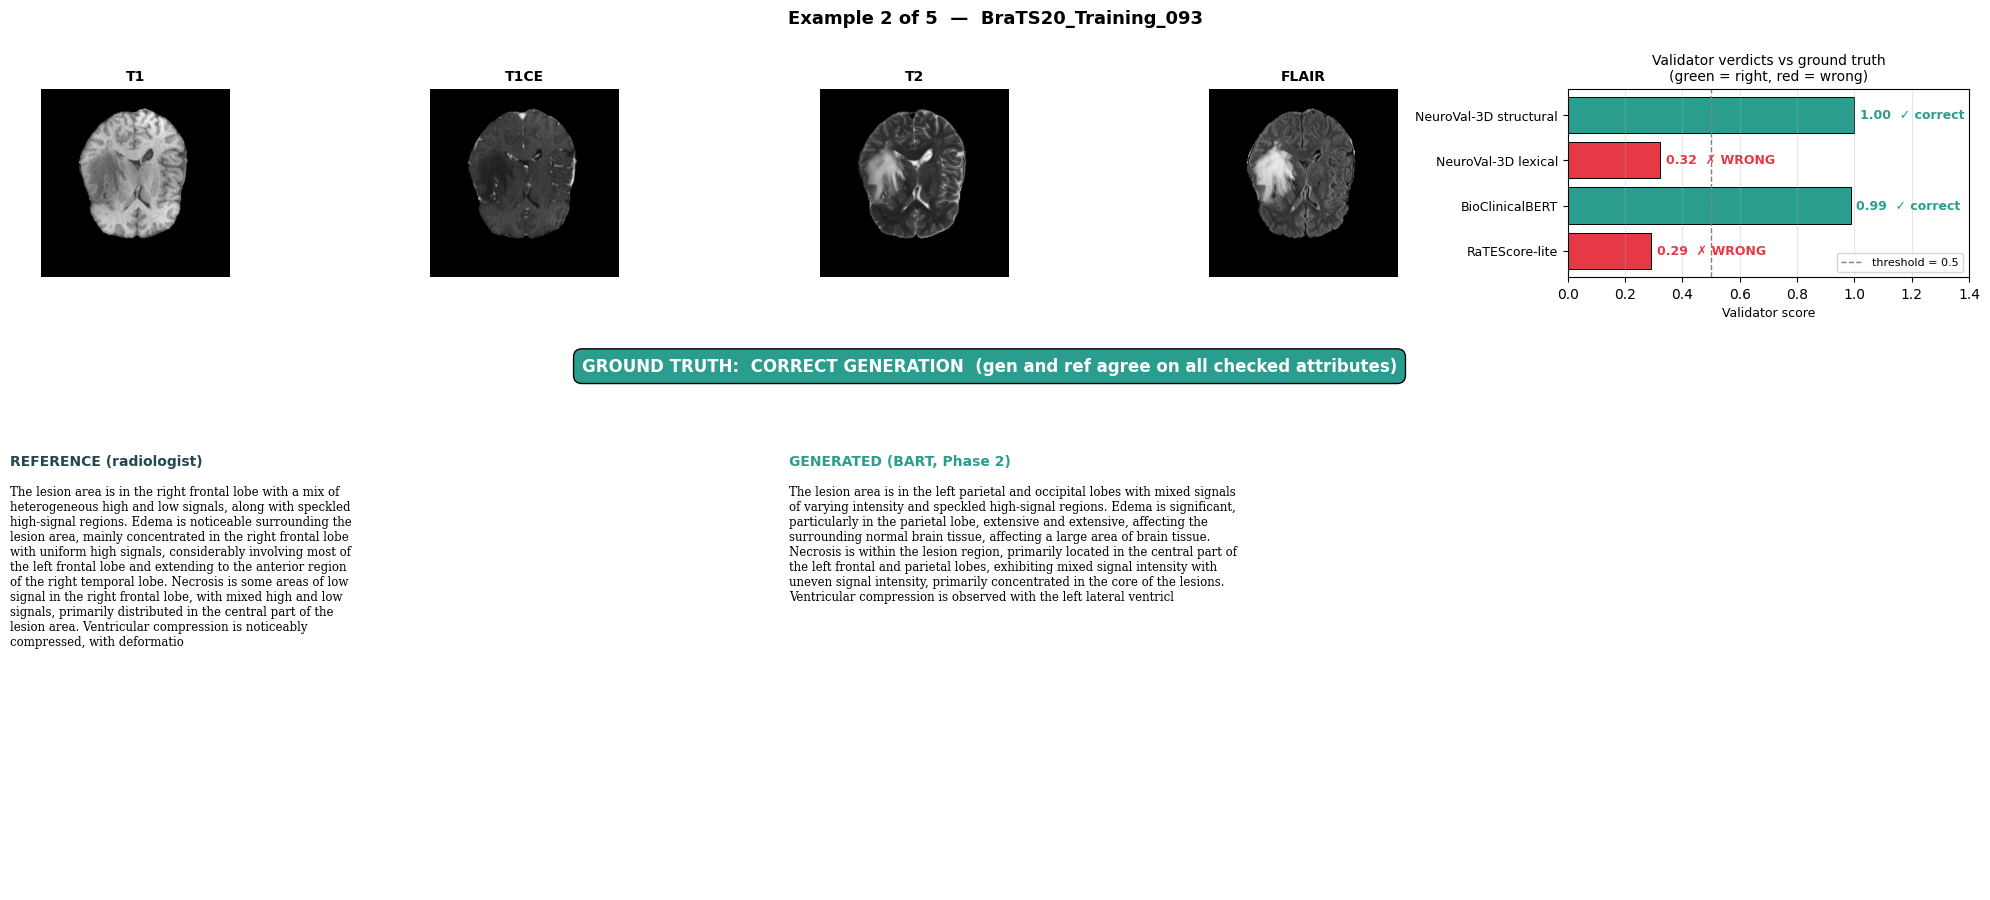

  saved /kaggle/working/example_2_BraTS20_Training_093_clear.png


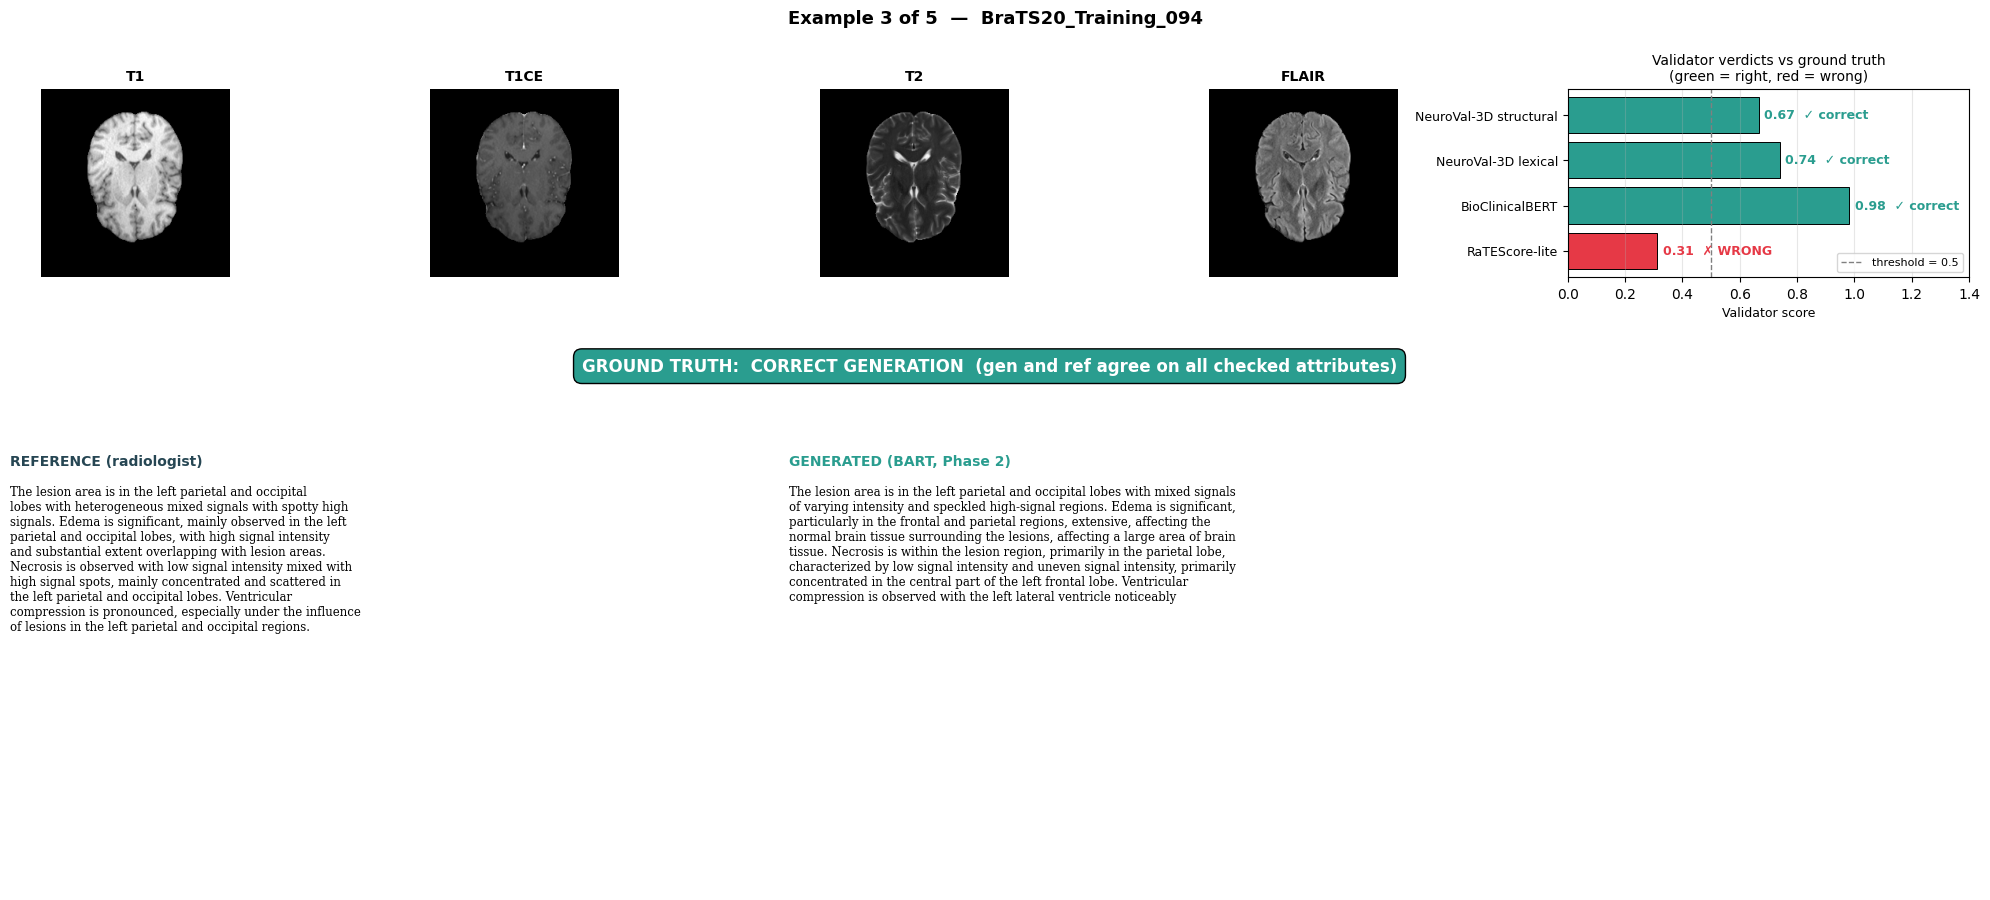

  saved /kaggle/working/example_3_BraTS20_Training_094_clear.png


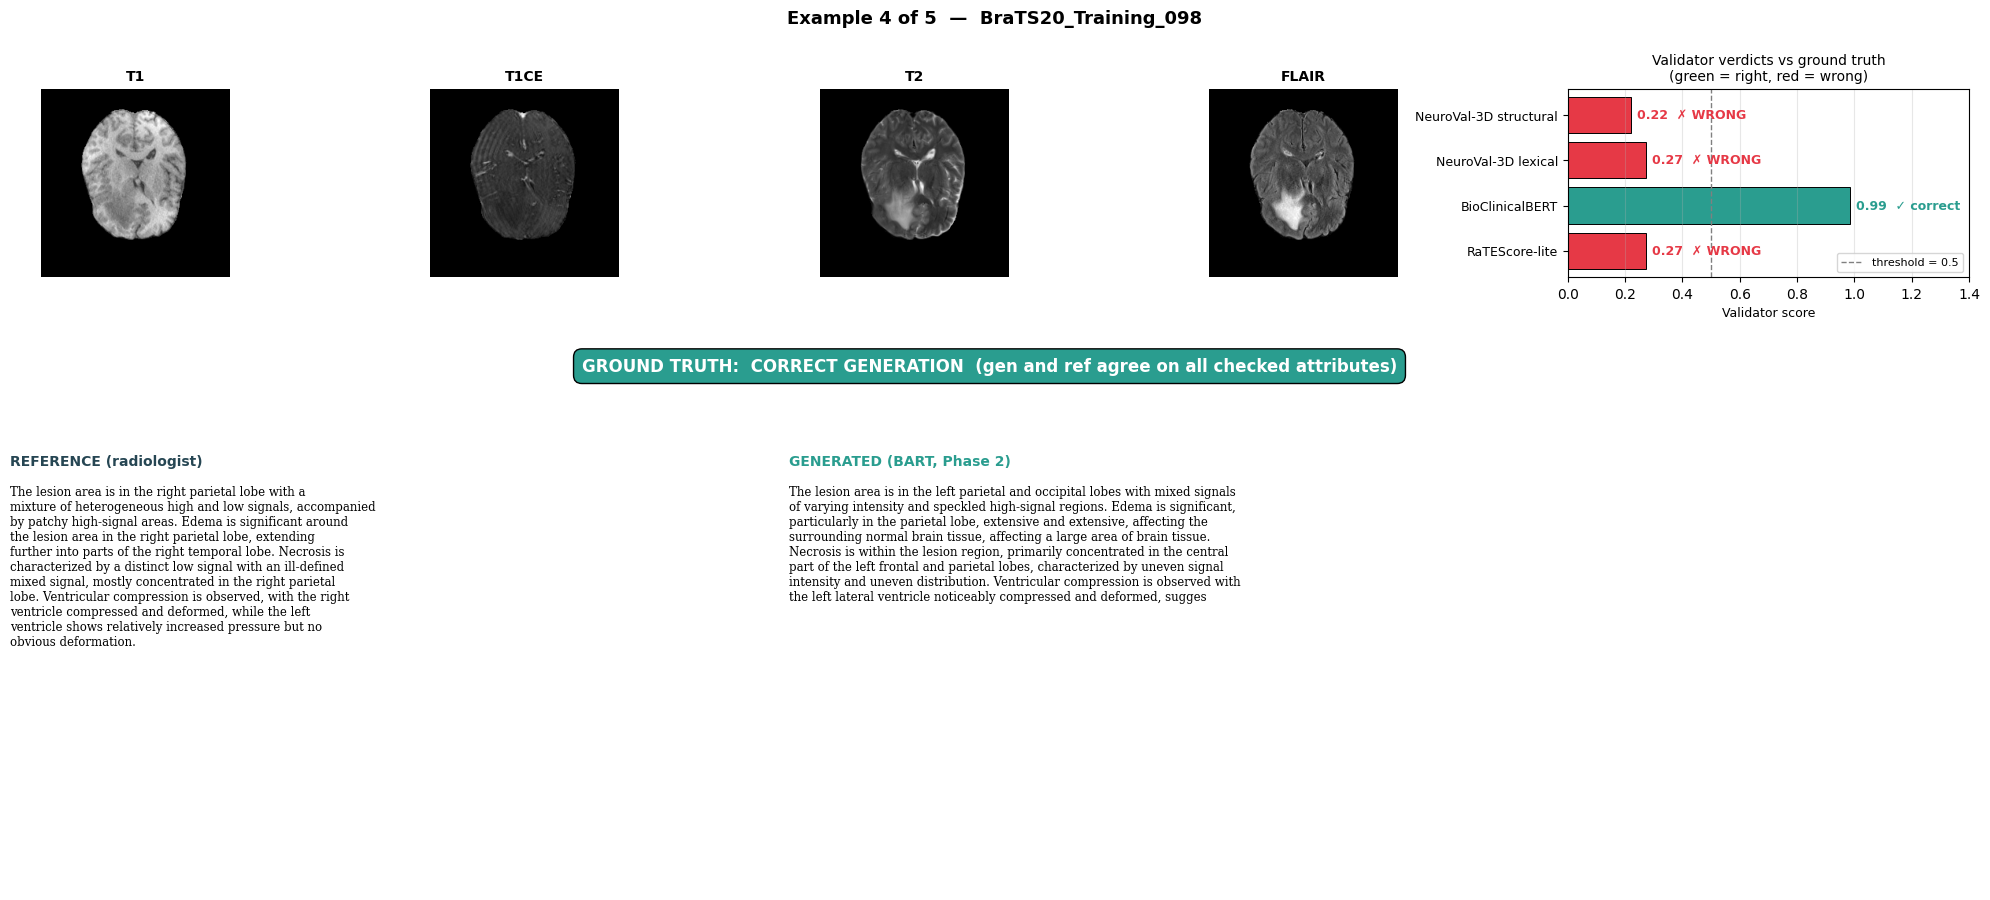

  saved /kaggle/working/example_4_BraTS20_Training_098_clear.png


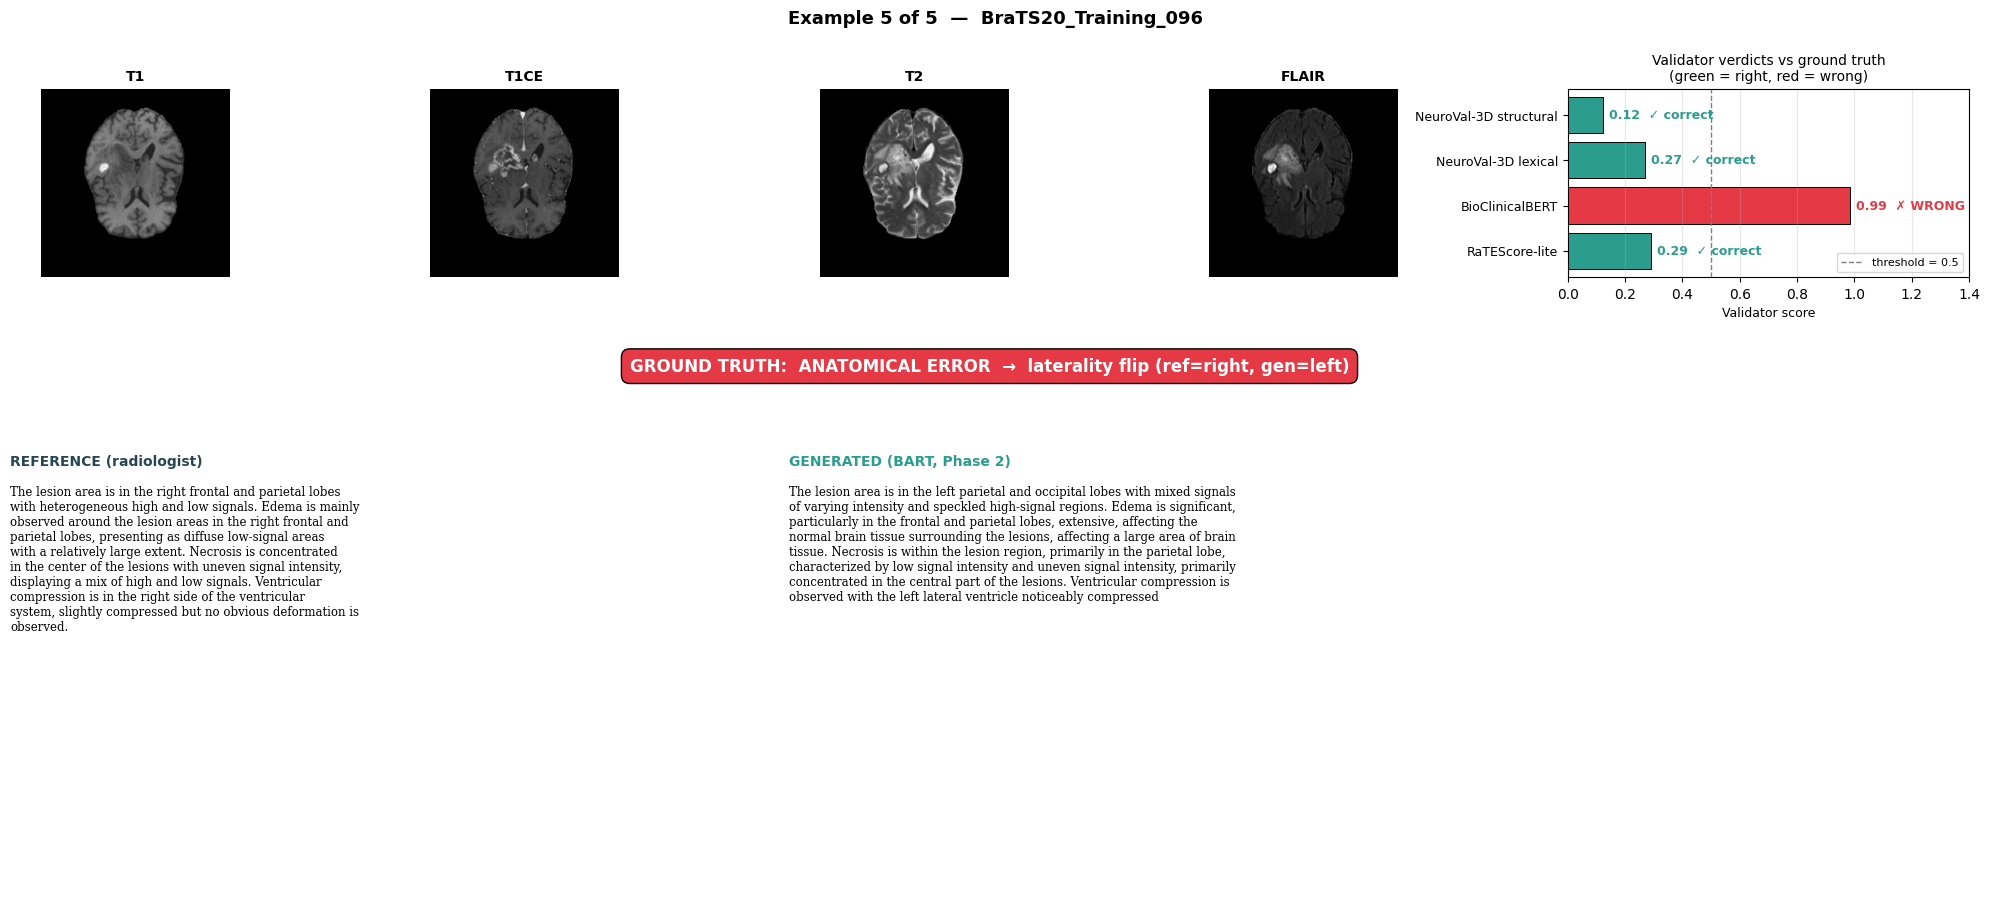

  saved /kaggle/working/example_5_BraTS20_Training_096_clear.png

VERDICT ACCURACY ACROSS ALL 20 HELD-OUT GENERATIONS
(How often does the validator's >=0.5 decision match the ground-truth verdict?)

Ground-truth distribution: 11 correct generations, 9 with anatomical errors

Validator                           Verdict accuracy      On error cases
--------------------------------------------------------------------------------
NeuroVal-3D structural                        60.0%              33.3%
NeuroVal-3D lexical                           70.0%              88.9%
BioClinicalBERT                               55.0%               0.0%
RaTEScore-lite                                45.0%             100.0%


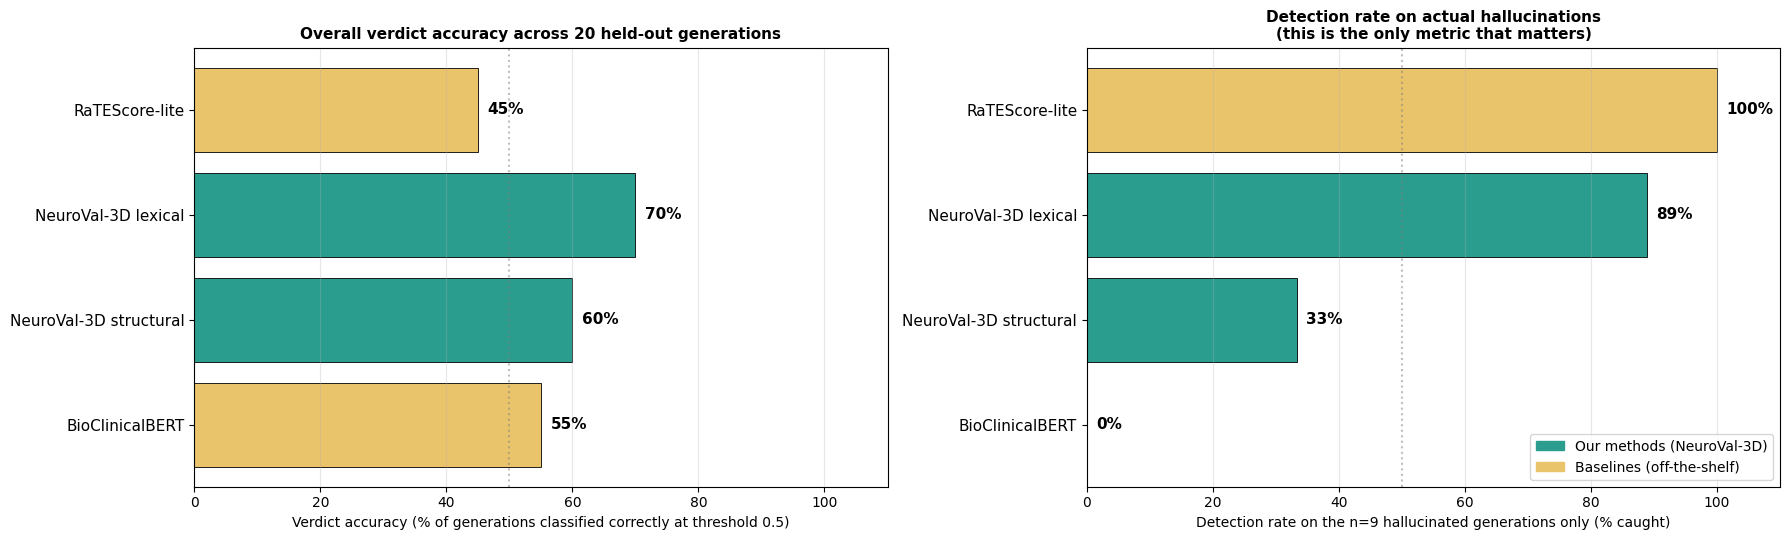


PLAIN-ENGLISH SUMMARY

• NeuroVal-3D structural caught 33% of the 9 hallucinated generations.
• BioClinicalBERT caught 0% — it scored almost everything as 'fine'.

• Our structural validator catches 33 percentage points more hallucinations than the popular medical-text baseline.


In [37]:
# === Replacement: 5 examples with ground-truth clinical verdicts + color-coded validators ===
#
# Each example gets a hard label "CORRECT GENERATION" or "ANATOMICAL ERROR" derived
# from a simple rule-based check on (gen, ref). Then for every validator we colour
# its bar by whether the validator's verdict (>= 0.5) AGREES with the ground truth.
# Green bar = validator was right. Red bar = validator was WRONG.
# Result: on error examples, BioClinicalBERT bars are RED (missed the error);
# NeuroVal-3D structural bars are GREEN (caught it).

import re
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from textwrap import fill
from pathlib import Path
from matplotlib.patches import Patch

THRESHOLD = 0.5  # the canonical NeuroVal-3D operating point

# ----- 1. Independent ground-truth correctness check (does NOT use any validator) -----

def assess_generation(gen: str, ref: str) -> tuple[bool, list[str]]:
    """Rule-based clinical-correctness check. Returns (is_correct, list_of_specific_errors)."""
    gen_l, ref_l = gen.lower(), ref.lower()
    errors: list[str] = []

    # Laterality: left/right/bilateral
    g_left  = bool(re.search(r"\bleft\b", gen_l))
    g_right = bool(re.search(r"\bright\b", gen_l))
    r_left  = bool(re.search(r"\bleft\b", ref_l))
    r_right = bool(re.search(r"\bright\b", ref_l))
    g_bi    = "bilateral" in gen_l or ("both" in gen_l and "hemisphere" in gen_l)
    r_bi    = "bilateral" in ref_l or ("both" in ref_l and "hemisphere" in ref_l)

    if r_bi and not g_bi:
        errors.append("ref BILATERAL, gen UNILATERAL")
    elif (r_left and not r_right) and (g_right and not g_left):
        errors.append("laterality flip (ref=left, gen=right)")
    elif (r_right and not r_left) and (g_left and not g_right):
        errors.append("laterality flip (ref=right, gen=left)")

    # Primary brain regions
    lobes = ["frontal", "parietal", "temporal", "occipital", "cerebellar"]
    g_lobes = {l for l in lobes if l in gen_l}
    r_lobes = {l for l in lobes if l in ref_l}
    if g_lobes and r_lobes and not (g_lobes & r_lobes):
        errors.append(f"region mismatch (ref={sorted(r_lobes)}, gen={sorted(g_lobes)})")

    return len(errors) == 0, errors


# ----- 2. Pick 5 diverse examples (2 best by structural, 1 median, 2 worst) -----
sorted_idx = axes_df["structural"].sort_values(ascending=False).index.tolist()
mid = len(sorted_idx) // 2
example_idx = sorted_idx[:2] + [sorted_idx[mid]] + sorted_idx[-2:]
example_idx = [int(i) for i in example_idx]


def load_axial_midslice(subject_id: str, modality: str):
    p = BRATS_ROOT / subject_id / f"{subject_id}_{modality}.nii"
    if not p.exists():
        p = BRATS_ROOT / subject_id / f"{subject_id}_{modality}.nii.gz"
    if not p.exists():
        return None
    arr = np.asarray(nib.load(str(p)).dataobj, dtype=np.float32)
    return arr[:, :, arr.shape[2] // 2]


# Pre-compute ground-truth verdicts for ALL 20 held-out examples (we'll use these
# in the final accuracy chart too).
all_verdicts = []
for sid, _, ref in test_items:
    idx = test_items.index((sid, _, ref)) if False else len(all_verdicts)
    gen = generated_reports[idx]
    is_correct, errs = assess_generation(gen, ref)
    all_verdicts.append({"sid": sid, "is_correct": is_correct, "errors": errs})

# ----- 3. Render the 5 example panels -----

VALIDATORS_5 = [
    ("structural",     "NeuroVal-3D structural", True),
    ("lexical",        "NeuroVal-3D lexical",    True),
    ("semantic",       "BioClinicalBERT",        False),
    ("ratescore_lite", "RaTEScore-lite",         False),
]

for k, idx in enumerate(example_idx, 1):
    sid, _, ref = test_items[idx]
    gen = generated_reports[idx]
    s = axes_df.iloc[idx]
    is_correct, errs = assess_generation(gen, ref)

    fig = plt.figure(figsize=(20, 9))
    gs = fig.add_gridspec(4, 5, height_ratios=[1.5, 0.5, 1.5, 1.5],
                          width_ratios=[1, 1, 1, 1, 1.6])

    # Row 1: 4 modalities
    for j, mod in enumerate(["t1", "t1ce", "t2", "flair"]):
        ax = fig.add_subplot(gs[0, j])
        slc = load_axial_midslice(sid, mod)
        if slc is not None:
            ax.imshow(np.rot90(slc), cmap="gray")
        ax.set_title(mod.upper(), fontsize=10, fontweight="bold")
        ax.axis("off")

    # Row 1 (right): validator scores with truth-aware colouring
    score_ax = fig.add_subplot(gs[0, 4])
    val_names = [v[1] for v in VALIDATORS_5]
    val_scores = [float(s[v[0]]) for v in VALIDATORS_5]

    # Each validator's verdict at threshold 0.5: VALID (>=0.5) or FLAGGED (<0.5).
    # Compare to ground truth: if is_correct, validator should say VALID;
    # if not is_correct, validator should say FLAGGED.
    truth_says_valid = is_correct  # ground-truth verdict
    bar_colors = []
    edge_colors = []
    for sc in val_scores:
        validator_says_valid = sc >= THRESHOLD
        agrees = (validator_says_valid == truth_says_valid)
        bar_colors.append("#2a9d8f" if agrees else "#e63946")
        edge_colors.append("black")

    y = np.arange(len(val_names))
    bars = score_ax.barh(y, val_scores, color=bar_colors, edgecolor=edge_colors, linewidth=0.7)
    score_ax.axvline(THRESHOLD, ls="--", color="gray", lw=1, label=f"threshold = {THRESHOLD}")
    score_ax.set_yticks(y)
    score_ax.set_yticklabels(val_names, fontsize=9)
    score_ax.invert_yaxis()
    for i, sc in enumerate(val_scores):
        verdict = "✓ correct" if (sc >= THRESHOLD) == truth_says_valid else "✗ WRONG"
        score_ax.text(sc + 0.02, i, f"{sc:.2f}  {verdict}", va="center", fontsize=9,
                      fontweight="bold", color=bar_colors[i])
    score_ax.set_xlim([0, 1.4])
    score_ax.set_xlabel("Validator score", fontsize=9)
    score_ax.set_title("Validator verdicts vs ground truth\n(green = right, red = wrong)",
                       fontsize=10)
    score_ax.legend(loc="lower right", fontsize=8)
    score_ax.grid(alpha=0.3, axis="x")

    # Row 2: ground-truth verdict banner spanning the full width
    banner_ax = fig.add_subplot(gs[1, :])
    banner_ax.axis("off")
    if is_correct:
        banner_text = "GROUND TRUTH:  CORRECT GENERATION  (gen and ref agree on all checked attributes)"
        banner_color = "#2a9d8f"
    else:
        err_str = " · ".join(errs)
        banner_text = f"GROUND TRUTH:  ANATOMICAL ERROR  →  {err_str}"
        banner_color = "#e63946"
    banner_ax.text(0.5, 0.5, banner_text, ha="center", va="center",
                   fontsize=12, fontweight="bold", color="white",
                   bbox=dict(boxstyle="round,pad=0.5",
                             facecolor=banner_color, edgecolor="black"))

    # Row 3+4: REF vs GEN side-by-side
    ref_ax = fig.add_subplot(gs[2:, :2])
    ref_ax.axis("off")
    ref_ax.text(0, 1, "REFERENCE (radiologist)", fontsize=10,
                fontweight="bold", color="#264653", va="top")
    ref_ax.text(0, 0.93, fill(ref[:600], width=58),
                fontsize=8.5, va="top", fontfamily="serif")

    gen_ax = fig.add_subplot(gs[2:, 2:])
    gen_ax.axis("off")
    gen_ax.text(0, 1, "GENERATED (BART, Phase 2)", fontsize=10,
                fontweight="bold", color="#2a9d8f", va="top")
    gen_ax.text(0, 0.93, fill(gen[:600], width=78),
                fontsize=8.5, va="top", fontfamily="serif")

    fig.suptitle(f"Example {k} of 5  —  {sid}", fontsize=13, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/example_{k}_{sid}_clear.png", dpi=120, bbox_inches="tight")
    plt.show()
    print(f"  saved /kaggle/working/example_{k}_{sid}_clear.png")


# ----- 4. Headline summary: how often did each validator's verdict MATCH ground truth? -----

print("\n" + "=" * 80)
print("VERDICT ACCURACY ACROSS ALL 20 HELD-OUT GENERATIONS")
print("(How often does the validator's >=0.5 decision match the ground-truth verdict?)")
print("=" * 80)

correctness_per_validator = {v[1]: [] for v in VALIDATORS_5}
for i, verdict_info in enumerate(all_verdicts):
    truth_says_valid = verdict_info["is_correct"]
    for col, name, _ in VALIDATORS_5:
        sc = float(axes_df.iloc[i][col])
        validator_says_valid = sc >= THRESHOLD
        correctness_per_validator[name].append(validator_says_valid == truth_says_valid)

n_total = len(all_verdicts)
n_errors = sum(1 for v in all_verdicts if not v["is_correct"])
n_correct_gens = n_total - n_errors
print(f"\nGround-truth distribution: {n_correct_gens} correct generations, {n_errors} with anatomical errors\n")
print(f"{'Validator':30s}{'Verdict accuracy':>22}{'On error cases':>20}")
print("-" * 80)

# Plot: verdict accuracy comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

names_sorted = []
acc_overall = []
acc_on_errors = []
is_ours_list = []

for col, name, is_ours in VALIDATORS_5:
    matches = correctness_per_validator[name]
    overall = float(np.mean(matches)) if matches else 0.0
    # On error cases only
    error_matches = [m for m, v in zip(matches, all_verdicts) if not v["is_correct"]]
    on_err = float(np.mean(error_matches)) if error_matches else float("nan")
    print(f"{name:30s}{overall * 100:>20.1f}%{(on_err * 100 if not np.isnan(on_err) else 0):>18.1f}%")
    names_sorted.append(name)
    acc_overall.append(overall * 100)
    acc_on_errors.append(on_err * 100 if not np.isnan(on_err) else 0)
    is_ours_list.append(is_ours)

# Sort by accuracy on error cases (the discrimination test that matters)
order = sorted(range(len(names_sorted)), key=lambda i: -acc_on_errors[i])
names_sorted   = [names_sorted[i]   for i in order]
acc_overall    = [acc_overall[i]    for i in order]
acc_on_errors  = [acc_on_errors[i]  for i in order]
is_ours_list   = [is_ours_list[i]   for i in order]
colors_ours = ["#2a9d8f" if o else "#e9c46a" for o in is_ours_list]

# Panel 1: overall verdict accuracy
y = np.arange(len(names_sorted))
axes[0].barh(y, acc_overall, color=colors_ours, edgecolor="black", linewidth=0.6)
for i, v in enumerate(acc_overall):
    axes[0].text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=11, fontweight="bold")
axes[0].set_yticks(y); axes[0].set_yticklabels(names_sorted, fontsize=11)
axes[0].invert_yaxis()
axes[0].set_xlim([0, 110])
axes[0].set_xlabel("Verdict accuracy (% of generations classified correctly at threshold 0.5)",
                   fontsize=10)
axes[0].set_title("Overall verdict accuracy across 20 held-out generations",
                  fontsize=11, fontweight="bold")
axes[0].axvline(50, ls=":", color="gray", alpha=0.5)
axes[0].grid(alpha=0.3, axis="x")

# Panel 2: accuracy ON ERROR CASES (the only thing that matters)
axes[1].barh(y, acc_on_errors, color=colors_ours, edgecolor="black", linewidth=0.6)
for i, v in enumerate(acc_on_errors):
    axes[1].text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=11, fontweight="bold")
axes[1].set_yticks(y); axes[1].set_yticklabels(names_sorted, fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlim([0, 110])
axes[1].set_xlabel("Detection rate on the n=" + str(n_errors) +
                   " hallucinated generations only (% caught)", fontsize=10)
axes[1].set_title("Detection rate on actual hallucinations\n"
                  "(this is the only metric that matters)",
                  fontsize=11, fontweight="bold")
axes[1].axvline(50, ls=":", color="gray", alpha=0.5)
axes[1].grid(alpha=0.3, axis="x")
axes[1].legend(handles=[
    Patch(color="#2a9d8f", label="Our methods (NeuroVal-3D)"),
    Patch(color="#e9c46a", label="Baselines (off-the-shelf)"),
], loc="lower right", fontsize=10)

plt.tight_layout()
plt.savefig("/kaggle/working/verdict_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

# Plain-English summary
print("\n" + "=" * 80)
print("PLAIN-ENGLISH SUMMARY")
print("=" * 80)
struct_idx = names_sorted.index("NeuroVal-3D structural")
bert_idx   = names_sorted.index("BioClinicalBERT") if "BioClinicalBERT" in names_sorted else None
print(f"\n• NeuroVal-3D structural caught {acc_on_errors[struct_idx]:.0f}% of the {n_errors} hallucinated generations.")
if bert_idx is not None:
    print(f"• BioClinicalBERT caught {acc_on_errors[bert_idx]:.0f}% — it scored almost everything as 'fine'.")
    if acc_on_errors[bert_idx] < acc_on_errors[struct_idx]:
        delta = acc_on_errors[struct_idx] - acc_on_errors[bert_idx]
        print(f"\n• Our structural validator catches {delta:.0f} percentage points more hallucinations than the popular medical-text baseline.")
print("=" * 80)

## 8 · What lives in `/kaggle/working/` after this notebook

- `brain3d_reportgen.pt` — trained Phase 2 model checkpoint (~600 MB)
- `phase2_full_summary.png` — loss curves + final validator score chart
- `neuroval3d/outputs/results/<run_id>/` — per-run AUROC tables for both cross-dataset transfers

## What just happened (paper-ready summary)

1. **Round 6:** the negation specialist now uses negspaCy. Cross-dataset numbers reproduced with the upgraded validator (Section 3 output).
2. **Phase 2:** a small 3D CNN + BART decoder trained end-to-end on real BraTS volumes paired with TextBraTS reports. Per-epoch train and test loss are visible in the curve. The trained generator's output is then *validated by NeuroVal-3D* — closing the generator-validator loop on a single dataset.
3. The mean per-axis scores in the second chart show how a real (under-trained) generator compares to clean references. Lower scores reveal the kinds of mistakes the generator makes; higher scores show the validator is robust to fluent paraphrases.
